In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1500

loans = pd.DataFrame({
    "Applicant_ID": range(1001, 1001 + n),
    "Age": np.random.randint(21, 66, n),
    "Monthly_Income_NGN": np.random.randint(80000, 1500000, n),
    "Loan_Amount_NGN": np.random.randint(100000, 5000000, n),
    "Loan_Term_Months": np.random.choice([6, 12, 24, 36, 48], n),
    "Credit_History": np.random.choice([0, 1], n, p=[0.25, 0.75]),
    "Employment_Years": np.random.randint(0, 26, n)
})

# Simulated default labels for learning purposes
risk_score = (
    (loans["Loan_Amount_NGN"] / loans["Monthly_Income_NGN"]) * 0.25
    + (1 - loans["Credit_History"]) * 2
    - loans["Employment_Years"] * 0.04
    + np.random.normal(0, 1, n)
)

loans["Default"] = (risk_score > 2.5).astype(int)

print("Dataset shape:", loans.shape)
print("\nDefault distribution:")
print(loans["Default"].value_counts())
display(loans.head())

Dataset shape: (1500, 8)

Default distribution:
Default
0    1174
1     326
Name: count, dtype: int64


,Applicant_ID,Age,Monthly_Income_NGN,Loan_Amount_NGN,Loan_Term_Months,Credit_History,Employment_Years,Default
0,1001,59,1052346,563001,12,1,1,0
1,1002,49,995015,3280246,48,0,8,1
2,1003,35,1078974,2251061,12,1,23,0
3,1004,63,511413,4050511,6,0,22,1
4,1005,28,1432564,2922136,48,1,2,0


In [2]:
# Overall default rate
default_rate = loans["Default"].mean() * 100

print(f"Total applicants: {len(loans)}")
print(f"Applicants who defaulted: {loans['Default'].sum()}")
print(f"Default rate: {default_rate:.2f}%")

# Compare borrowers by repayment outcome
risk_summary = loans.groupby("Default").agg(
    Applicants=("Applicant_ID", "count"),
    Average_Income=("Monthly_Income_NGN", "mean"),
    Average_Loan=("Loan_Amount_NGN", "mean"),
    Average_Employment=("Employment_Years", "mean"),
    Credit_History_Rate=("Credit_History", "mean")
).round(2)

risk_summary.index = ["Non-Default", "Default"]
display(risk_summary)

Total applicants: 1500
Applicants who defaulted: 326
Default rate: 21.73%


,Applicants,Average_Income,Average_Loan,Average_Employment,Credit_History_Rate
Non-Default,1174,881294.19,2336967.41,13.14,0.84
Default,326,515438.90,3130598.24,10.26,0.40


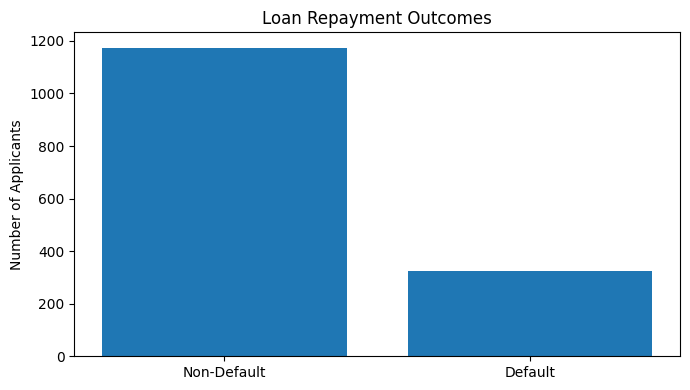

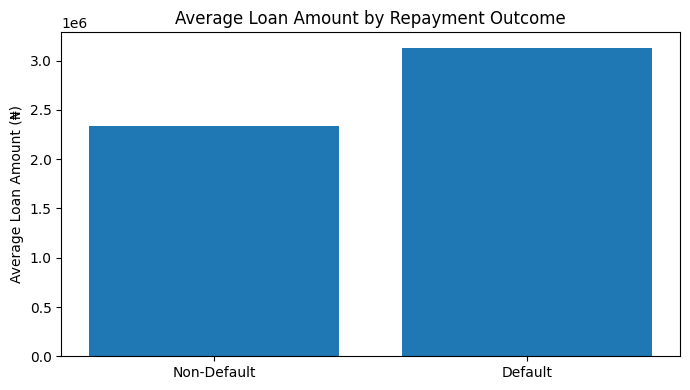

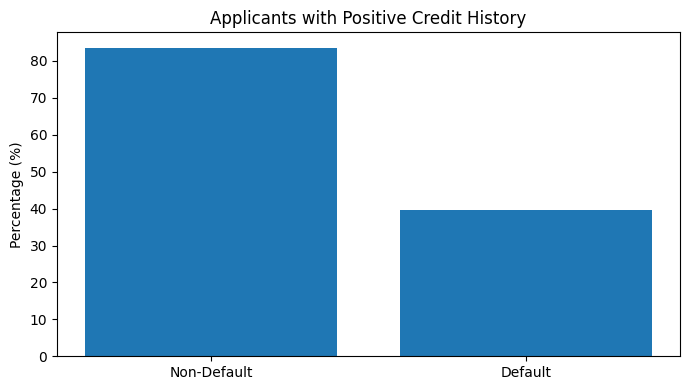

In [3]:
import matplotlib.pyplot as plt

# Chart 1: Default vs non-default applicants
counts = loans["Default"].value_counts().reindex([0, 1], fill_value=0)

plt.figure(figsize=(7, 4))
plt.bar(["Non-Default", "Default"], counts.values)
plt.title("Loan Repayment Outcomes")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

# Chart 2: Average loan amount by outcome
avg_loan = loans.groupby("Default")["Loan_Amount_NGN"].mean()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Non-Default", "Default"],
    [avg_loan.get(0, 0), avg_loan.get(1, 0)]
)
plt.title("Average Loan Amount by Repayment Outcome")
plt.ylabel("Average Loan Amount (₦)")
plt.tight_layout()
plt.show()

# Chart 3: Credit history by outcome
credit_history = loans.groupby("Default")["Credit_History"].mean() * 100

plt.figure(figsize=(7, 4))
plt.bar(
    ["Non-Default", "Default"],
    [credit_history.get(0, 0), credit_history.get(1, 0)]
)
plt.title("Applicants with Positive Credit History")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Prepare features and target
X = loans.drop(columns=["Applicant_ID", "Default"])
y = loans["Default"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    )
}

# Train and evaluate models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 3),
        "Precision": round(precision_score(
            y_test, predictions, zero_division=0
        ), 3),
        "Recall": round(recall_score(
            y_test, predictions, zero_division=0
        ), 3),
        "F1 Score": round(f1_score(
            y_test, predictions, zero_division=0
        ), 3),
        "ROC-AUC": round(roc_auc_score(y_test, probabilities), 3)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.827,0.623,0.508,0.559,0.911
1,Random Forest,0.883,0.768,0.662,0.711,0.926


LOAN DEFAULT FEATURE IMPORTANCE


,Feature,Importance
1,Monthly_Income_NGN,0.348110
4,Credit_History,0.222808
2,Loan_Amount_NGN,0.192096
5,Employment_Years,0.107734
0,Age,0.087114
3,Loan_Term_Months,0.042138


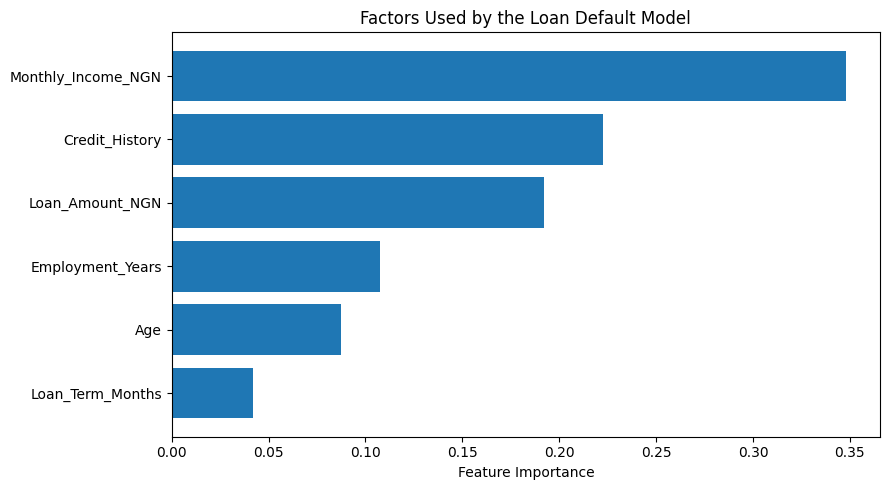

In [6]:
# Get feature importance from the trained Random Forest
rf_model = models["Random Forest"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("LOAN DEFAULT FEATURE IMPORTANCE")
display(importance)

# Visualize the results
plt.figure(figsize=(9, 5))
plt.barh(
    importance["Feature"][::-1],
    importance["Importance"][::-1]
)

plt.title("Factors Used by the Loan Default Model")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [7]:
# Overall portfolio summary
total_applicants = len(loans)
default_count = int(loans["Default"].sum())
default_rate = loans["Default"].mean() * 100

print("=" * 45)
print("LOAN DEFAULT RISK ANALYSIS")
print("=" * 45)

print(f"Total applicants: {total_applicants:,}")
print(f"Applicants labelled as default: {default_count:,}")
print(f"Simulated default rate: {default_rate:.2f}%")

print("\nMODEL PERFORMANCE")
display(results_df)

print("\nBUSINESS RECOMMENDATIONS")
print("1. Assess loan affordability relative to verified income.")
print("2. Consider credit history alongside other relevant evidence.")
print("3. Monitor repayment outcomes and portfolio default rates.")
print("4. Evaluate model precision and recall before operational use.")
print("5. Validate findings on real, representative loan data.")

LOAN DEFAULT RISK ANALYSIS
Total applicants: 1,500
Applicants labelled as default: 326
Simulated default rate: 21.73%

MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.827,0.623,0.508,0.559,0.911
1,Random Forest,0.883,0.768,0.662,0.711,0.926



BUSINESS RECOMMENDATIONS
1. Assess loan affordability relative to verified income.
2. Consider credit history alongside other relevant evidence.
3. Monitor repayment outcomes and portfolio default rates.
4. Evaluate model precision and recall before operational use.
5. Validate findings on real, representative loan data.


# Loan Default Risk Analysis and Prediction

## Objective
Explore borrower characteristics associated with simulated loan defaults and develop machine-learning models to classify repayment risk.

## Tools Used
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Analysis Performed
- Generated a simulated dataset of 1,500 loan applicants.
- Examined default rates and borrower characteristics.
- Compared loan amounts and credit history across repayment outcomes.
- Visualized loan risk patterns.
- Trained Logistic Regression and Random Forest classifiers.
- Evaluated models using accuracy, precision, recall, F1 score, and ROC-AUC.
- Examined feature importance and developed business recommendations.

## Business Relevance
Loan risk analytics can help financial institutions investigate borrower affordability, monitor portfolio performance, and evaluate credit-risk models.

## Limitations
The data and default labels are synthetic. The labels were generated using selected borrower characteristics, so the model results do not demonstrate predictive performance on actual Nigerian borrowers. The analysis is educational and must not be used to approve or reject real loan applicants.

## Future Improvements
Use a genuine, appropriately licensed credit-risk dataset; validate model performance on unseen real-world data; evaluate fairness and explainability; and assess the financial costs of false-positive and false-negative predictions.